# Problems: Categorical and Numeric Variables
**Completed solutions for Q1–Q6**  
Source: uploaded `problems (2).pdf` (September 15, 2026). Run cells top to bottom. Q6 requires the separate `./data/metabric.csv` dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.figsize"] = (7, 4)

## Q1. One-hot encoding, sample proportions, and ECDF
**(a)** Encode `[red, blue, blue, red, green, grey]` using one column per label. **(b)** Find the sample proportion for each label. **(c)** Find and sketch the empirical CDF of `X = [1, 3, 3, 6, 11]`.

In [2]:
colors = pd.Series(["red", "blue", "blue", "red", "green", "grey"], name="color")
one_hot = pd.get_dummies(colors).astype(int).reindex(columns=["red", "blue", "green", "grey"])
print("(a) One-hot encoding:\n", one_hot.to_string(index=False))
proportions = one_hot.mean()
print("\n(b) Sample proportions:\n", proportions.to_string())

(a) One-hot encoding:
  red  blue  green  grey
   1     0      0     0
   0     1      0     0
   0     1      0     0
   1     0      0     0
   0     0      1     0
   0     0      0     1

(b) Sample proportions:
 red      0.333333
blue     0.333333
green    0.166667
grey     0.166667


**Answer (b):** red = 2/6 = 1/3; blue = 2/6 = 1/3; green = 1/6; grey = 1/6.

**Answer (c):** The ECDF is $\hat F_n(x)=\frac{1}{5}\sum_{i=1}^5\mathbf{1}(X_i\le x)$. Thus it equals 0 for $x<1$, 1/5 for $1\le x<3$, 3/5 for $3\le x<6$, 4/5 for $6\le x<11$, and 1 for $x\ge11$. The jump at 3 is 2/5 because 3 occurs twice.

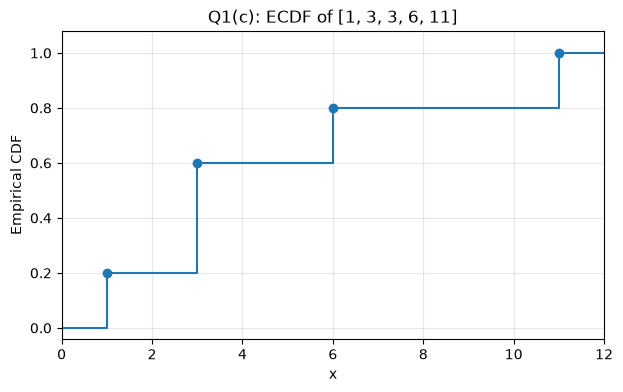

In [3]:
x = np.array([1, 3, 3, 6, 11]); xs = np.sort(x); ys = np.arange(1, len(xs)+1)/len(xs)
plt.step(np.r_[0, xs, 12], np.r_[0, ys, 1], where="post")
plt.scatter([1,3,6,11], [0.2,0.6,0.8,1], zorder=3)
plt.xlim(0,12); plt.ylim(-0.04,1.08); plt.xlabel("x"); plt.ylabel("Empirical CDF"); plt.title("Q1(c): ECDF of [1, 3, 3, 6, 11]"); plt.grid(alpha=.3); plt.show()

## Q2. Linear and nonlinear transformations
**(a)** For $Y=a+bX$ with $b>0$, derive its CDF and PDF. **(b–d)** For $X=[1,3,4]$, compare the mean, mean of squares, and squared mean.

**(a) Derivation:** $F_Y(y)=P(a+bX\le y)=P(X\le (y-a)/b)=F_X((y-a)/b)$. If $X$ has density $f_X$, the chain rule gives $f_Y(y)=\frac1b f_X((y-a)/b)$.

**(b)** $\bar x=(1+3+4)/3=8/3$. **(c)** $\overline{x^2}=(1+9+16)/3=26/3$. **(d)** $(\bar x)^2=64/9$, not $26/3=78/9$. The difference is $14/9$, the population-form variance of these observations.

In [4]:
sample = np.array([1.,3.,4.]); mean = sample.mean(); mean_square = (sample**2).mean(); square_mean = mean**2
print(f"(b) Mean = {mean:.6f} = 8/3")
print(f"(c) Mean of squares = {mean_square:.6f} = 26/3")
print(f"(d) Square of mean = {square_mean:.6f} = 64/9")
print(f"Equal? {np.isclose(mean_square,square_mean)}; difference = {mean_square-square_mean:.6f} = 14/9")

(b) Mean = 2.666667 = 8/3
(c) Mean of squares = 8.666667 = 26/3
(d) Square of mean = 7.111111 = 64/9
Equal? False; difference = 1.555556 = 14/9


## Q3. Exponential distribution
Given $F_X(x)=0$ for $x<0$ and $F_X(x)=1-e^{-x}$ for $x\ge0$.

**(a)** Its density is $f_X(x)=e^{-x}$ for $x\ge0$, zero otherwise. **(b)** $P(X\ge3)=e^{-3}\approx0.049787$; $P(X\le35)=1-e^{-35}\approx0.9999999999999993$.

**(c)** For $Y=1+3X$, $F_Y(y)=0$ for $y<1$ and $1-e^{-(y-1)/3}$ for $y\ge1$. Its density is $f_Y(y)=\frac13 e^{-(y-1)/3}$ for $y\ge1$, zero otherwise. $P(Y<10)=F_Y(10)=1-e^{-3}\approx0.950213$.

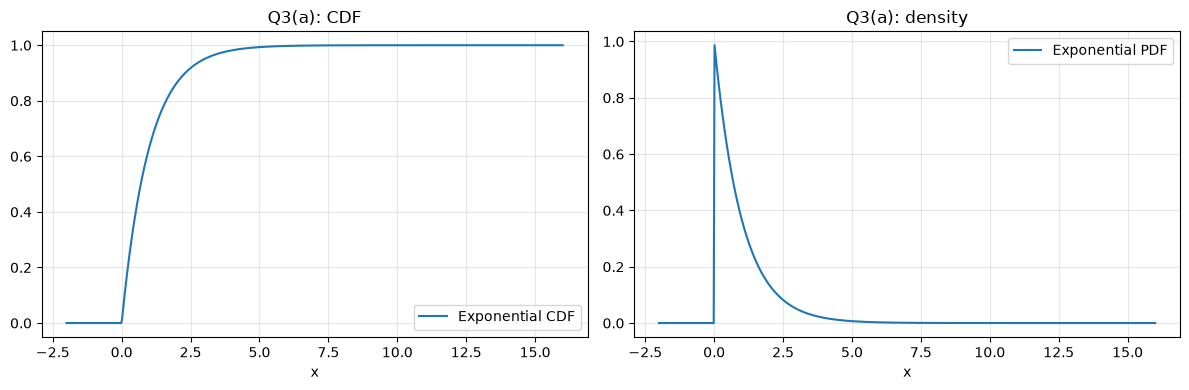

P(X >= 3) = 0.049787068367863944
P(X <= 35) = 0.9999999999999993


In [5]:
t=np.linspace(-2,16,600)
exp_cdf=np.where(t<0,0,1-np.exp(-np.maximum(t,0)))
exp_pdf=np.where(t<0,0,np.exp(-np.maximum(t,0)))
fig, ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(t,exp_cdf,label="Exponential CDF"); ax[1].plot(t,exp_pdf,label="Exponential PDF")
for a in ax: a.set_xlabel("x"); a.grid(alpha=.3); a.legend()
ax[0].set_title("Q3(a): CDF"); ax[1].set_title("Q3(a): density"); plt.tight_layout(); plt.show()
print("P(X >= 3) =", np.exp(-3)); print("P(X <= 35) =", -np.expm1(-35))

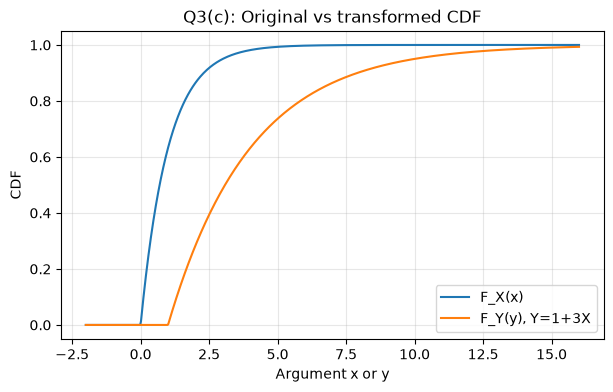

P(Y < 10) = 0.950212931632136


In [6]:
fy=np.where(t<1,0,1-np.exp(-np.maximum(t-1,0)/3))
plt.plot(t,exp_cdf,label="F_X(x)"); plt.plot(t,fy,label="F_Y(y), Y=1+3X")
plt.xlabel("Argument x or y"); plt.ylabel("CDF"); plt.title("Q3(c): Original vs transformed CDF"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("P(Y < 10) =",1-np.exp(-3))

## Q4. Logistic distribution
Given $F_X(x)=\frac{1}{1+e^{-x}}$.

**(a)** Differentiate to get $f_X(x)=\frac{e^{-x}}{(1+e^{-x})^2}=F_X(x)(1-F_X(x))$.

**(b)** $P(X\ge0.8)=1-F_X(0.8)\approx0.310026$ and $P(X\le0.3)=F_X(0.3)\approx0.574443$.

**(c)** For $Y=2X-1$, $F_Y(y)=F_X((y+1)/2)=\frac{1}{1+e^{-(y+1)/2}}$ for all real $y$. Also $f_Y(y)=\frac12 f_X((y+1)/2)$. $P(Y<0)=F_X(0.5)\approx0.622459$.

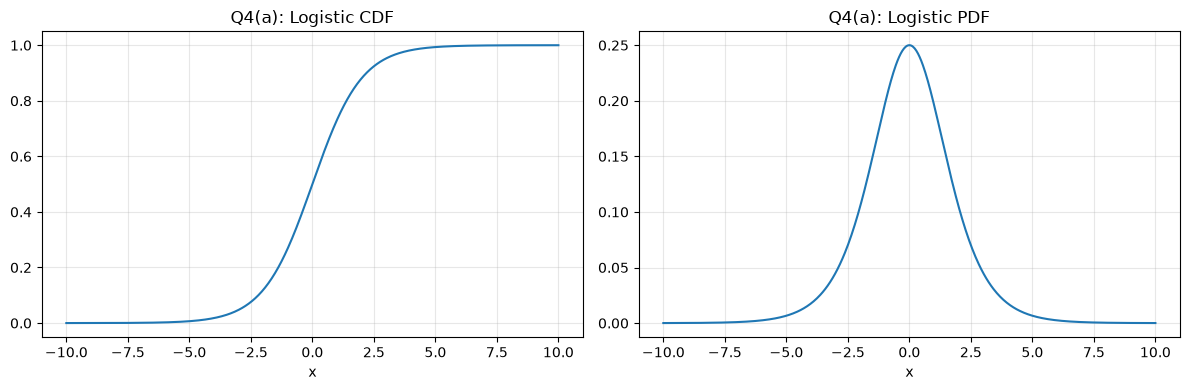

P(X >= 0.8) = 0.3100255188723875
P(X <= 0.3) = 0.574442516811659


In [7]:
def logistic(z): return 1/(1+np.exp(-z))
t=np.linspace(-10,10,600); fx=logistic(t); pdf=fx*(1-fx)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(t,fx);ax[0].set_title("Q4(a): Logistic CDF")
ax[1].plot(t,pdf);ax[1].set_title("Q4(a): Logistic PDF")
for a in ax: a.set_xlabel("x"); a.grid(alpha=.3)
plt.tight_layout();plt.show()
print("P(X >= 0.8) =",1-logistic(.8))
print("P(X <= 0.3) =",logistic(.3))

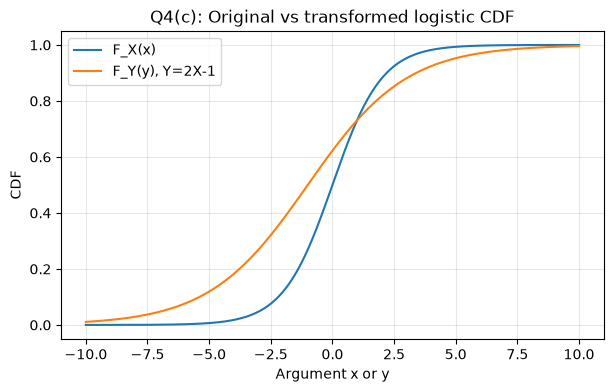

P(Y < 0) = 0.6224593312018546


In [8]:
plt.plot(t,logistic(t),label="F_X(x)");plt.plot(t,logistic((t+1)/2),label="F_Y(y), Y=2X-1")
plt.title("Q4(c): Original vs transformed logistic CDF");plt.xlabel("Argument x or y");plt.ylabel("CDF");plt.grid(alpha=.3);plt.legend();plt.show()
print("P(Y < 0) =",logistic(.5))

## Q5. Medians and quantile functions
**(a)** Exponential median: solve $1-e^{-m}=1/2$, giving $m=\ln2\approx0.693147$.

**(b)** Logistic median: solve $1/(1+e^{-m})=1/2$, giving $m=0$.

**(c)** Exponential quantile: $u=1-e^{-x}\Rightarrow Q_X(u)=-\ln(1-u)$ for $0<u<1$. At $u=0$, the quantile is 0; as $u\to1^-$, it diverges to infinity.

**(d)** Logistic quantile: $u=1/(1+e^{-x})\Rightarrow Q_X(u)=\ln\big(\frac{u}{1-u}\big)$ for $0<u<1$. Endpoint limits are $-\infty$ and $+\infty$.

In [9]:
u=np.array([.1,.25,.5,.75,.9]); qexp=-np.log1p(-u); qlog=np.log(u/(1-u))
print("Exponential median:",np.log(2),"; logistic median:",0)
print(pd.DataFrame({"u":u,"Exponential quantile":qexp,"Logistic quantile":qlog}).to_string(index=False))

Exponential median: 0.6931471805599453 ; logistic median: 0
   u  Exponential quantile  Logistic quantile
0.10              0.105361          -2.197225
0.25              0.287682          -1.098612
0.50              0.693147           0.000000
0.75              1.386294           1.098612
0.90              2.302585           2.197225


## Q6. METABRIC overall survival and chemotherapy

**(a)** Plot the ECDF of `Overall Survival (Months)`. **(b)** Plot the ECDF by `Chemotherapy`, and discuss the association. **(c)** Explain whether the observational plot establishes chemotherapy effectiveness.

In [3]:
csv_path = Path("./data/metabric.csv")
if not csv_path.exists():
    print(f"Missing {csv_path}. Put the METABRIC CSV in a data/ folder next to this notebook, then rerun Q6.")
else:
    metabric = pd.read_csv(csv_path)
    print("Dataset shape:", metabric.shape)
    print("Columns:", list(metabric.columns))

Dataset shape: (1343, 14)
Columns: ['Age at Diagnosis', 'Type of Breast Surgery', 'Cancer Type', 'Chemotherapy', 'Hormone Therapy', 'Lymph nodes examined positive', 'Mutation Count', 'Nottingham prognostic index', 'Overall Survival (Months)', 'Overall Survival Status', 'Radio Therapy', 'TMB (nonsynonymous)', 'Tumor Size', 'Tumor Stage']


Rows with survival measurements: 1343


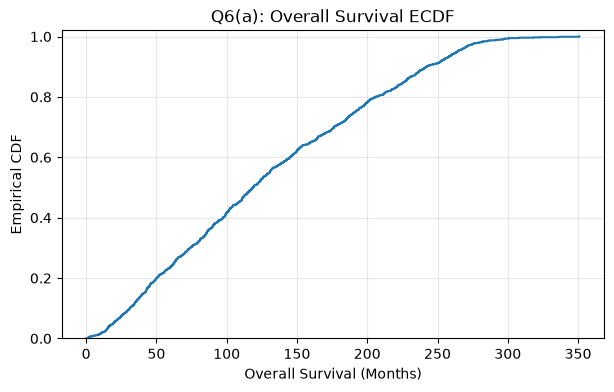

In [4]:
if csv_path.exists():
    survival_col = "Overall Survival (Months)"
    chemo_col = "Chemotherapy"
    if survival_col not in metabric or chemo_col not in metabric:
        raise KeyError(f"Expected columns {survival_col!r} and {chemo_col!r}; inspect printed columns and update names if needed.")
    df = metabric[[survival_col,chemo_col]].copy()
    df[survival_col] = pd.to_numeric(df[survival_col],errors="coerce")
    df = df.dropna(subset=[survival_col])
    print("Rows with survival measurements:",len(df))
    def plot_ecdf(values, label=None):
        values=np.sort(np.asarray(values,dtype=float))
        if len(values):
            plt.step(values,np.arange(1,len(values)+1)/len(values),where="post",label=label)
    plot_ecdf(df[survival_col]);plt.title("Q6(a): Overall Survival ECDF")
    plt.xlabel("Overall Survival (Months)");plt.ylabel("Empirical CDF");plt.ylim(0,1.02);plt.grid(alpha=.3);plt.show()

Survival by chemotherapy label:
               count        mean      median
Chemotherapy                               
NO             1057  135.737496  125.266667
YES             286  104.542308   90.266667


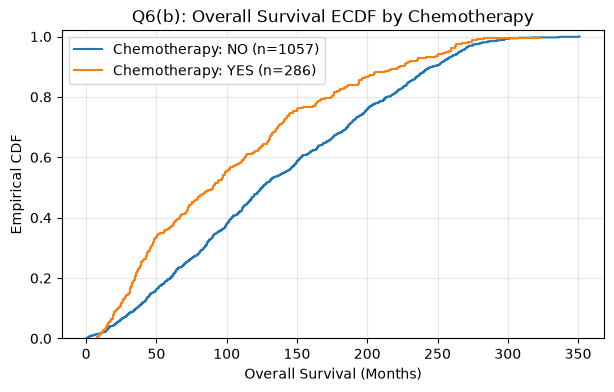


Interpretation: At a fixed survival time, a LOWER ECDF indicates a larger fraction of patients surviving beyond that time in the observed records.
Compare curves across times; crossing curves mean no uniform longer/shorter association.


In [5]:
if csv_path.exists():
    grouped=df.dropna(subset=[chemo_col]).groupby(chemo_col,dropna=False)
    summary=grouped[survival_col].agg(["count","mean","median"]).sort_index()
    print("Survival by chemotherapy label:\n",summary.to_string())
    for name,part in grouped:
        plot_ecdf(part[survival_col],label=f"Chemotherapy: {name} (n={len(part)})")
    plt.title("Q6(b): Overall Survival ECDF by Chemotherapy")
    plt.xlabel("Overall Survival (Months)");plt.ylabel("Empirical CDF")
    plt.ylim(0,1.02);plt.legend();plt.grid(alpha=.3);plt.show()
    print("\nInterpretation: At a fixed survival time, a LOWER ECDF indicates a larger fraction of patients surviving beyond that time in the observed records.")
    print("Compare curves across times; crossing curves mean no uniform longer/shorter association.")

### Q6(b) and Q6(c): Interpretation and limitations

**(b) Answer:** Based on the graph, patients who received chemotherapy generally had shorter survival times since the orange curve is higher than the blue curve for most of the graph.

**(c) Answer:** We can't determine whether chemotherapy is effective just from these graphs. It could just be that patients who needed chemotherapy had more serious cases of cancer. We would need to know more about the patients and their conditions before deciding if chemotherapy actually helps.